### **00. Import Libs and the DataSet**

In [ ]:
#Install Dependencies
!pip install fg-data-profiling

In [2]:
#Import Data Profile Tool
from data_profiling import ProfileReport

In [3]:
#Import Specific Libs
from scipy import stats
from google.colab import files;
from collections import Counter;
from IPython.display import IFrame, display, HTML;

In [4]:
#Import the Others Libs
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import plotly.express as px
import seaborn as sns
import pandas as pd
import numpy as np
import re

In [5]:
#Import Statistical and Time Series Libs
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.graphics.mosaicplot import mosaic
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [6]:
#Ignore Error Message
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [7]:
#Import Dataframe from Github
df = pd.read_csv('https://raw.githubusercontent.com/jrafa1607/DataScience-ML-AI/main/-%20Datasets/credit_data.csv')

### **01. Manual Data Profiling**

In [8]:
#Database Visualization with Print
print(df)

      i#clientid        income        age         loan  c#default
0              1  66155.925095  59.017015  8106.532131          0
1              2  34415.153966  48.117153  6564.745018          0
2              3  57317.170063  63.108049  8020.953296          0
3              4  42709.534201  45.751972  6103.642260          0
4              5  66952.688845  18.584336  8770.099235          1
...          ...           ...        ...          ...        ...
1995        1996  59221.044874  48.518179  1926.729397          0
1996        1997  69516.127573  23.162104  3503.176156          0
1997        1998  44311.449262  28.017167  5522.786693          1
1998        1999  43756.056605  63.971796  1622.722598          0
1999        2000  69436.579552  56.152617  7378.833599          0

[2000 rows x 5 columns]


In [9]:
#Database Visualization with Interactive Table
df.head(3)

,i#clientid,income,age,loan,c#default
0,1,66155.925095,59.017015,8106.532131,0
1,2,34415.153966,48.117153,6564.745018,0
2,3,57317.170063,63.108049,8020.953296,0


In [10]:
#Attributes View
print(df.columns)

Index(['i#clientid', 'income', 'age', 'loan', 'c#default'], dtype='object')


In [11]:
#Define New Attributes Names
df.columns = ['id', 'income', 'age', 'loan', 'result']
df.head(3)

,id,income,age,loan,result
0,1,66155.925095,59.017015,8106.532131,0
1,2,34415.153966,48.117153,6564.745018,0
2,3,57317.170063,63.108049,8020.953296,0


In [12]:
#Change the Name of the Specific Attribute
df = df.rename(columns={df.columns[0]: "Index"})
df.head(3)

,Index,income,age,loan,result
0,1,66155.925095,59.017015,8106.532131,0
1,2,34415.153966,48.117153,6564.745018,0
2,3,57317.170063,63.108049,8020.953296,0


In [13]:
#Total of Rows and Attributes
df.shape

(2000, 5)

In [14]:
#Show the Dataframe Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Index   2000 non-null   int64  
 1   income  2000 non-null   float64
 2   age     1997 non-null   float64
 3   loan    2000 non-null   float64
 4   result  2000 non-null   int64  
dtypes: float64(3), int64(2)
memory usage: 78.3 KB


In [15]:
#Search Uniques Values (Values, Count, Percentage and Most Frequently)
print(df.result.value_counts(), "\n")
print(df.result.value_counts(normalize=True) * 100, "\n")

result
0    1717
1     283
Name: count, dtype: int64 

result
0    85.85
1    14.15
Name: proportion, dtype: float64 



In [16]:
#Show the Most Frequent Value in the Attribute
print(df['result'].mode())

0    0
Name: result, dtype: int64


In [17]:
#Describe the DataFrame
df.describe()

,Index,income,age,loan,result
count,2000.000000,2000.000000,1997.000000,2000.000000,2000.000000
mean,1000.500000,45331.600018,40.807559,4444.369695,0.141500
std,577.494589,14326.327119,13.624469,3045.410024,0.348624
min,1.000000,20014.489470,-52.423280,1.377630,0.000000
25%,500.750000,32796.459717,28.990415,1939.708847,0.000000
50%,1000.500000,45789.117313,41.317159,3974.719419,0.000000
75%,1500.250000,57791.281668,52.587040,6432.410625,0.000000
max,2000.000000,69995.685578,63.971796,13766.051239,1.000000


In [18]:
#Correlation Matrix Between the Attributes
df.corr()

,Index,income,age,loan,result
Index,1.000000,0.039280,-0.014704,0.018931,-0.020145
income,0.039280,1.000000,-0.033687,0.441117,0.002284
age,-0.014704,-0.033687,1.000000,0.002309,-0.429759
loan,0.018931,0.441117,0.002309,1.000000,0.377160
result,-0.020145,0.002284,-0.429759,0.377160,1.000000


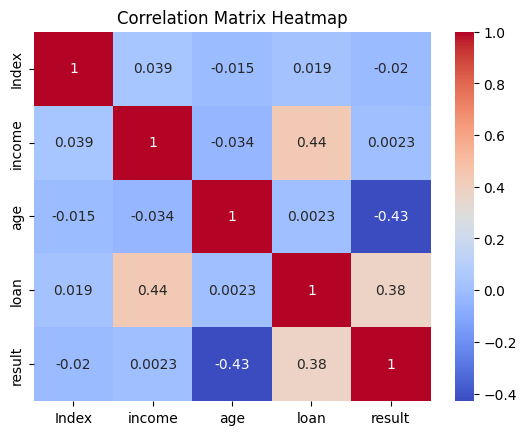

In [19]:
#Correlation Matrix Heatmap
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix Heatmap')
plt.show()

In [20]:
#Define the Numerical Attributes and the Target
num_cols = ['income', 'age', 'loan']
target = 'result'

In [21]:
#Unique Values per Attribute ( Cardinality )
cardinality = pd.DataFrame({
    'dtype': df.dtypes,
    'unique_values': df.nunique(),
    'unique_%': (df.nunique() / len(df) * 100).round(2)
})
cardinality

,dtype,unique_values,unique_%
Index,int64,2000,100.00
income,float64,2000,100.00
age,float64,1997,99.85
loan,float64,2000,100.00
result,int64,2,0.10


In [22]:
#Extended Descriptive Statistics ( Median, IQR, CV, Skewness and Kurtosis )
# Skewness: ~0 symmetric | > 1 right-skewed | < -1 left-skewed
# CV (Coefficient of Variation) = std / mean: compares the spread of attributes with different scales
extended = pd.DataFrame({
    'mean': df[num_cols].mean(),
    'median': df[num_cols].median(),
    'std': df[num_cols].std(),
    'iqr': df[num_cols].quantile(0.75) - df[num_cols].quantile(0.25),
    'cv_%': df[num_cols].std() / df[num_cols].mean() * 100,
    'skewness': df[num_cols].skew(),
    'kurtosis': df[num_cols].kurt()
}).round(2)
extended

,mean,median,std,iqr,cv_%,skewness,kurtosis
income,45331.60,45789.12,14326.33,24994.82,31.60,-0.04,-1.20
age,40.81,41.32,13.62,23.60,33.39,-0.31,0.55
loan,4444.37,3974.72,3045.41,4492.70,68.52,0.62,-0.34


In [23]:
#Normality Test ( D'Agostino-Pearson )
# H0: the attribute follows a normal distribution ( p-value < 0.05 rejects H0 )
# With a large sample the test rejects even tiny deviations: always check the Q-Q plot too ( Example 16 )
for col in num_cols:
    stat, p_value = stats.normaltest(df[col].dropna())
    print(f'{col:<8} statistic = {stat:>8.2f} | p-value = {p_value:.2e} | {"Normal" if p_value > 0.05 else "Not Normal"}')

income   statistic =  1630.51 | p-value = 0.00e+00 | Not Normal
age      statistic =    46.78 | p-value = 6.95e-11 | Not Normal
loan     statistic =   124.81 | p-value = 7.89e-28 | Not Normal


In [24]:
#Spearman Correlation Matrix ( Rank-Based: Robust to Outliers and Captures Monotonic Relations )
df[num_cols + [target]].corr(method='spearman').round(3)

,income,age,loan,result
income,1.000,-0.034,0.402,0.002
age,-0.034,1.000,0.009,-0.440
loan,0.402,0.009,1.000,0.370
result,0.002,-0.440,0.370,1.000


In [25]:
#Correlation of Each Attribute with the Target
corr_target = pd.DataFrame({
    'pearson': df[num_cols].corrwith(df[target]),
    'spearman': df[num_cols].corrwith(df[target], method='spearman')
}).round(3)
corr_target.sort_values('pearson', key=abs, ascending=False)

,pearson,spearman
age,-0.430,-0.440
loan,0.377,0.370
income,0.002,0.002


### **02. Automatic Data Profiling**

In [26]:
#Automatic Data Profiling
profile = ProfileReport(df, minimal=True);
profile.to_file(output_file="output.html");

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 5/5 [00:00<00:00, 41.51it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

### **03. Check for Issues in the Dataframe**

In [27]:
#Check for the Null Values
print(df.isnull().sum())

Index     0
income    0
age       3
loan      0
result    0
dtype: int64


In [28]:
#Percentage of Missing Values
missing = pd.DataFrame({
    'missing_count': df.isnull().sum(),
    'missing_%': (df.isnull().mean() * 100).round(2)
})
missing

,missing_count,missing_%
Index,0,0.00
income,0,0.00
age,3,0.15
loan,0,0.00
result,0,0.00


In [29]:
#Search for Negative Values
print(df[df['age'] < 0])

    Index        income        age         loan  result
15     16  50501.726689 -28.218361  3977.287432       0
21     22  32197.620701 -52.423280  4244.057136       0
26     27  63287.038908 -36.496976  9595.286289       0


In [30]:
#Second Example (Query) for Negative Values
df.query("age < 0")

,Index,income,age,loan,result
15,16,50501.726689,-28.218361,3977.287432,0
21,22,32197.620701,-52.423280,4244.057136,0
26,27,63287.038908,-36.496976,9595.286289,0


In [31]:
#Check for Duplicated Rows
print('Duplicated rows ( all attributes ):', df.duplicated().sum())
print('Duplicated rows ( ignoring Index ):', df.drop(columns='Index').duplicated().sum())
print('Duplicated Index values:', df['Index'].duplicated().sum())

Duplicated rows ( all attributes ): 0
Duplicated rows ( ignoring Index ): 0
Duplicated Index values: 0


### **04. Graphics & Illustrations**

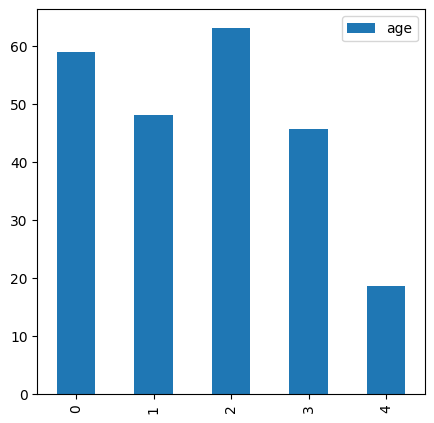

In [32]:
#Example 01
df[['age']].head(5).plot.bar(figsize=(5, 5));

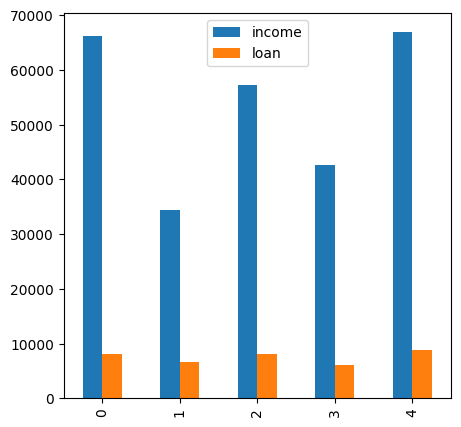

In [33]:
#Example 02
df[['income', 'loan']].head(5).plot.bar(figsize=(5, 5));

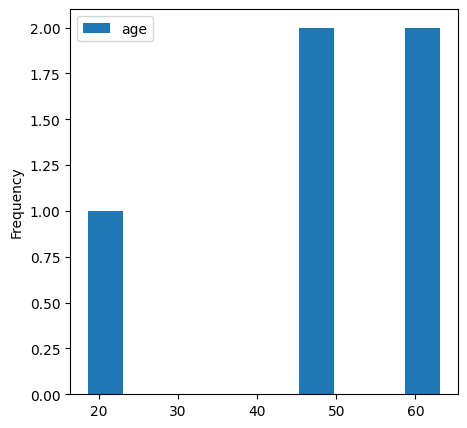

In [34]:
#Example 03
df[['age']].head(5).plot.hist(figsize=(5, 5));

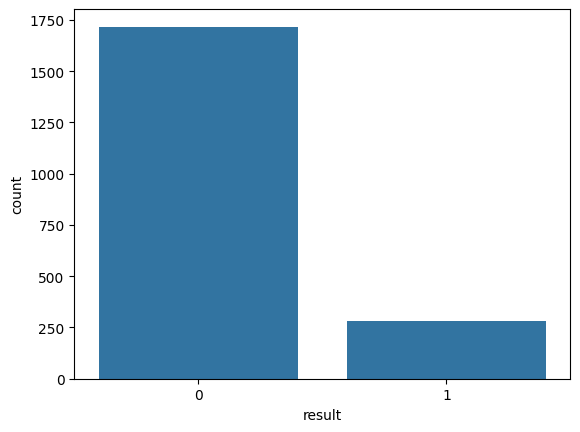

In [35]:
#Example 04
sns.countplot(x = df['result']);

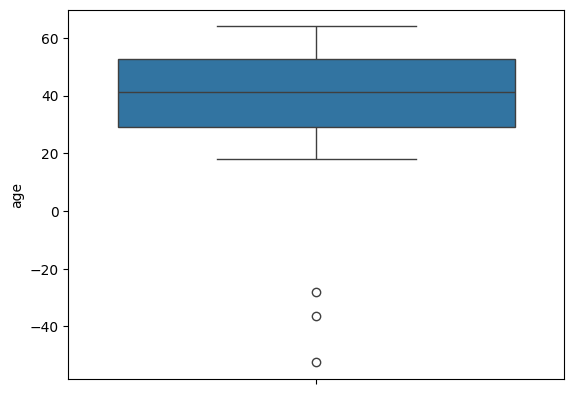

In [36]:
#Example 05 ( Attribute Distribution )
sns.boxplot(df.age);

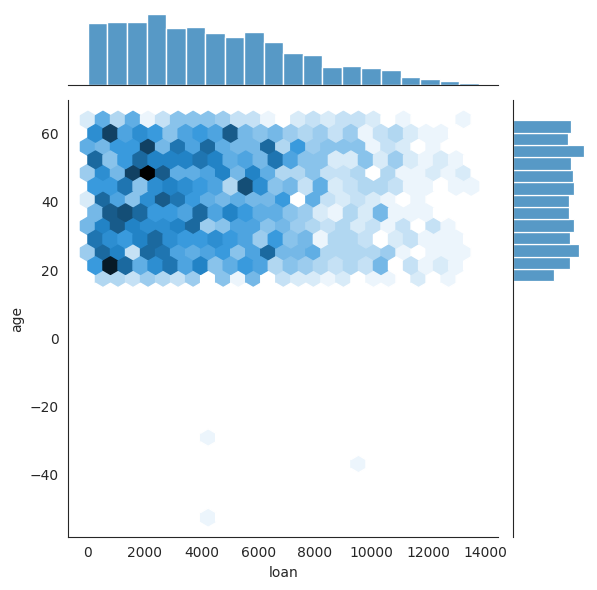

In [37]:
#Example 06 ( Another Attribute Distribution )
with sns.axes_style('white'):
    sns.jointplot(x = df['loan'], y = df['age'], kind='hex');

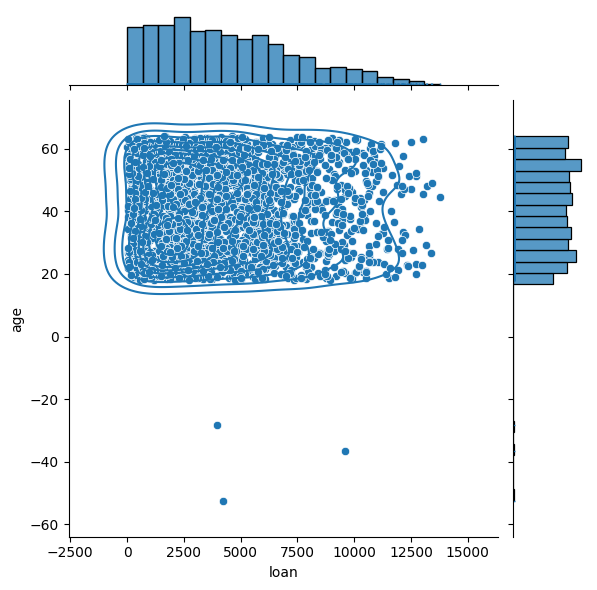

In [38]:
#Example 07 ( Another Attribute Distribution )
sns.jointplot(data=df, x='loan', y='age').plot_joint(sns.kdeplot).plot_marginals(sns.rugplot);

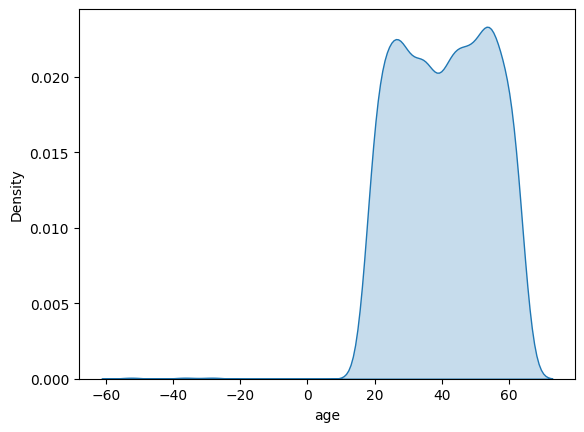

In [39]:
#Example 08 ( Histogram )
sns.kdeplot(x = df['age'], shade=True);

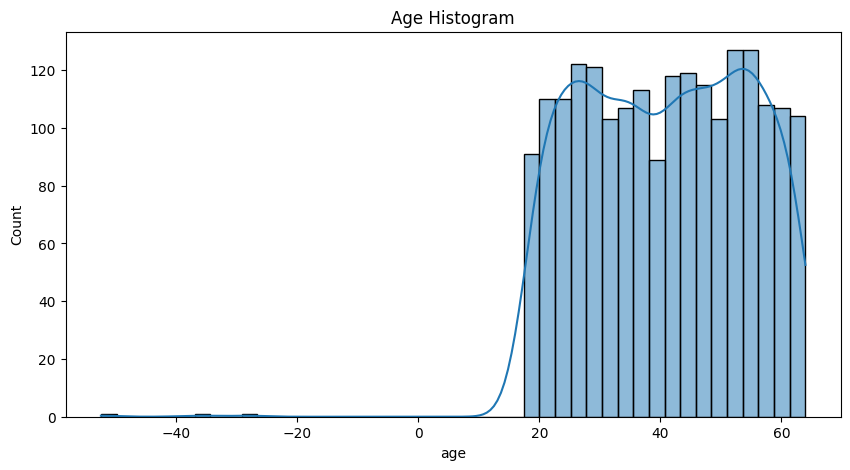

In [40]:
#Example 09 ( Another Example of Histogram )
plt.figure(figsize=(10,5));
sns.histplot(df["age"], kde=True, bins=45)
plt.title("Age Histogram");

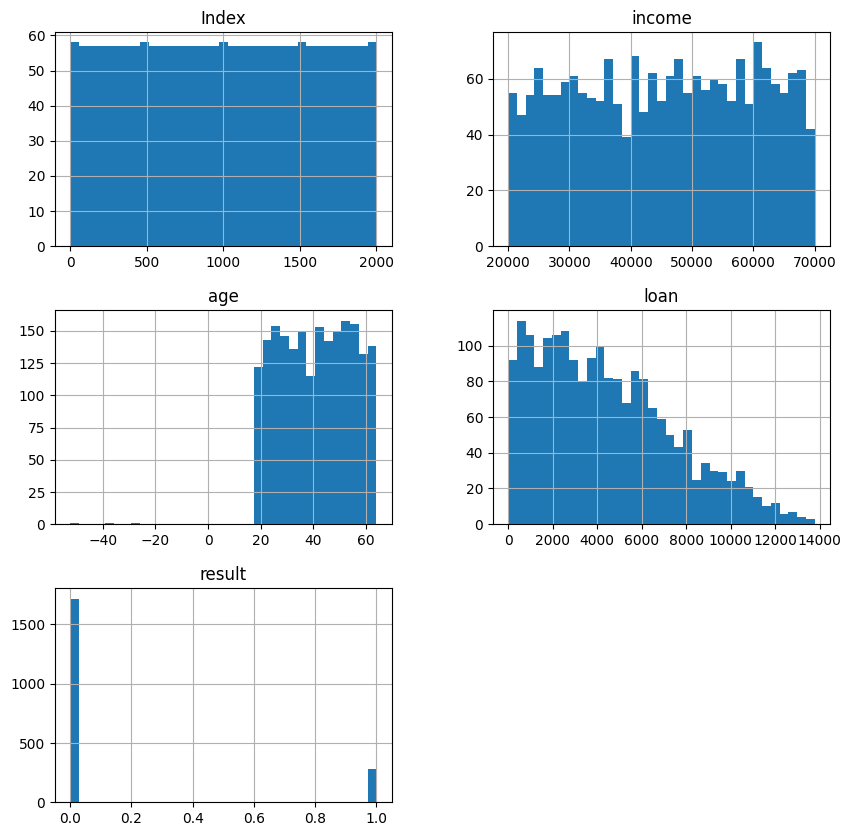

In [41]:
#Example 10 ( All Histograms )
df.hist(bins=35, figsize=(10, 10))
plt.show()

<Axes: xlabel='age', ylabel='Count'>

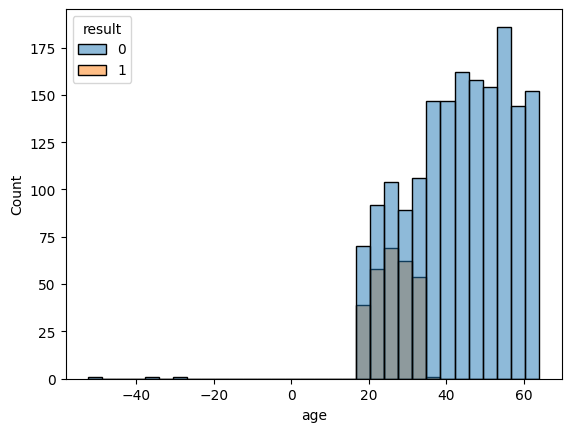

In [42]:
#Example 11 ( Combine Histograms )
sns.histplot(data=df, x="age", hue="result")

In [43]:
#Example 12 ( Scatter Matrix )
graph = px.scatter_matrix(df, dimensions=['age', 'income', 'loan'], color = 'result')
graph.show()

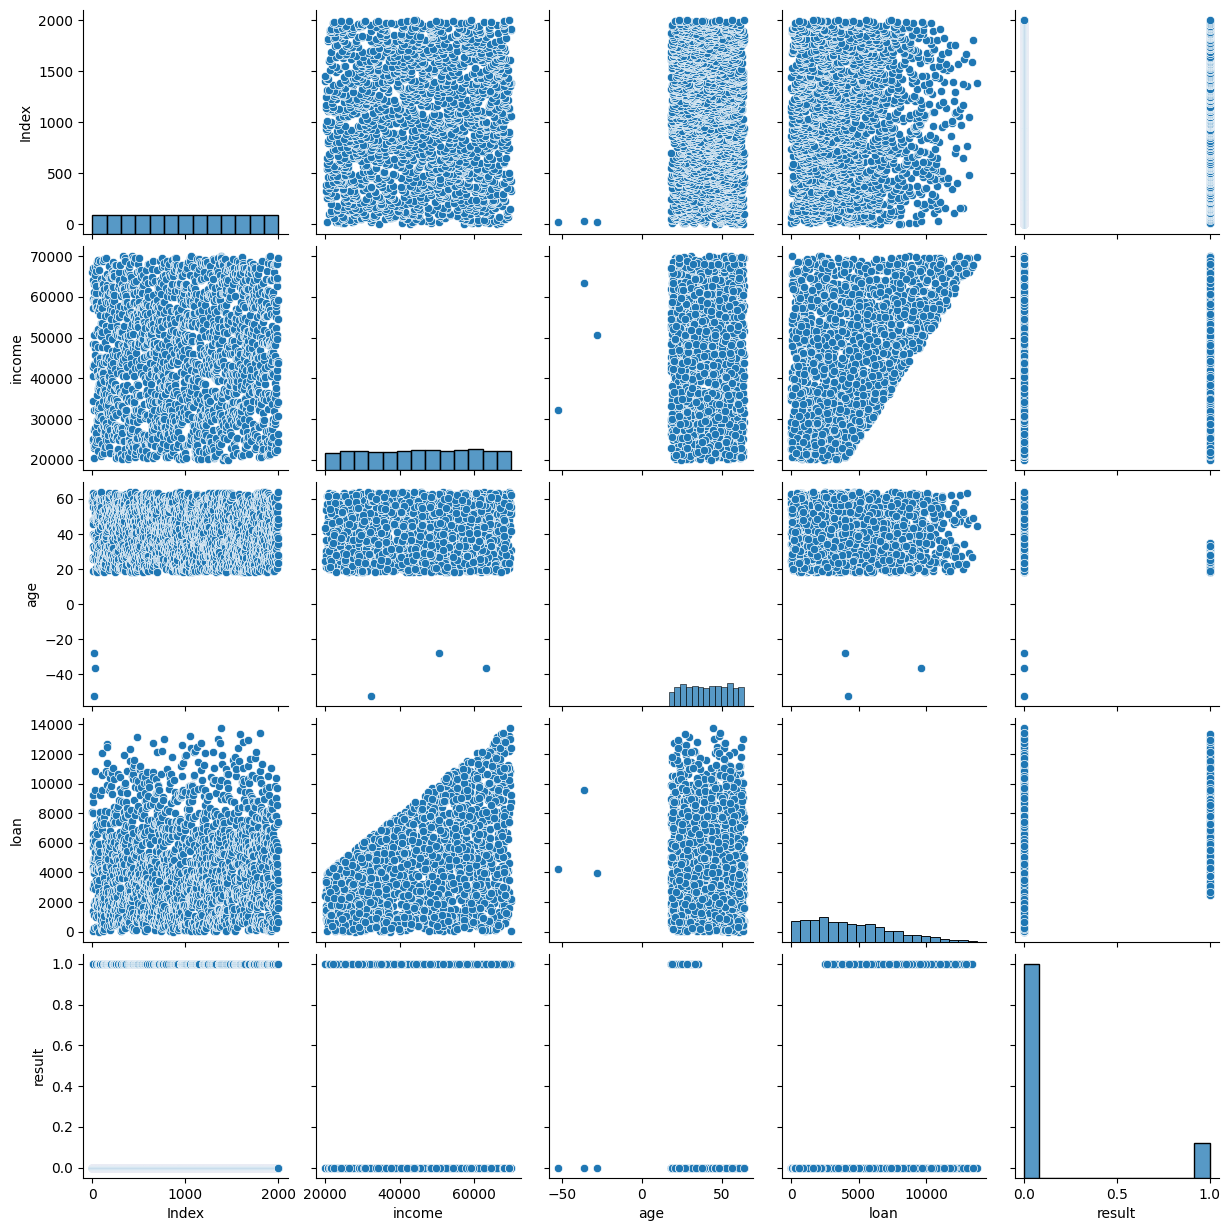

In [44]:
#Example 13 ( Full Fair Plot )
sns.pairplot(df);

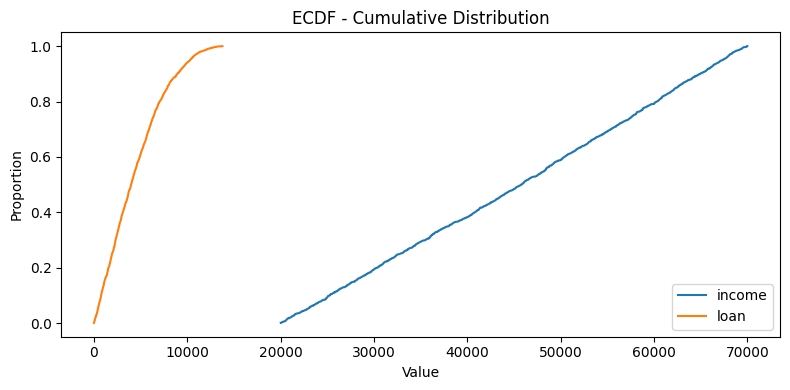

In [45]:
#Example 14 ECDF (Empirical Cumulative Distribution Function)
fig, ax = plt.subplots(figsize=(8, 4))

for col in ['income', 'loan']:
    # Remove Null Values // Sort Values for ECDF
    s = df[col].dropna().sort_values()
    ax.plot(s.values, np.arange(1, len(s) + 1) / len(s), label=col)

ax.set_title('ECDF - Cumulative Distribution')
ax.set_xlabel('Value')
ax.set_ylabel('Proportion')
ax.legend()
plt.tight_layout()
plt.show()

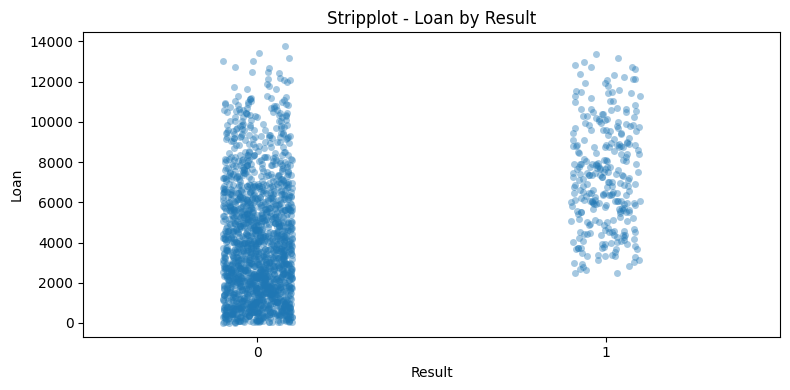

In [46]:
# Example 15 with Stripplot
plt.figure(figsize=(8, 4))
sns.stripplot(data=df.dropna(), x='result', y='loan', alpha=0.4)
plt.title('Stripplot - Loan by Result')
plt.xlabel('Result')
plt.ylabel('Loan')
plt.tight_layout()
plt.show()

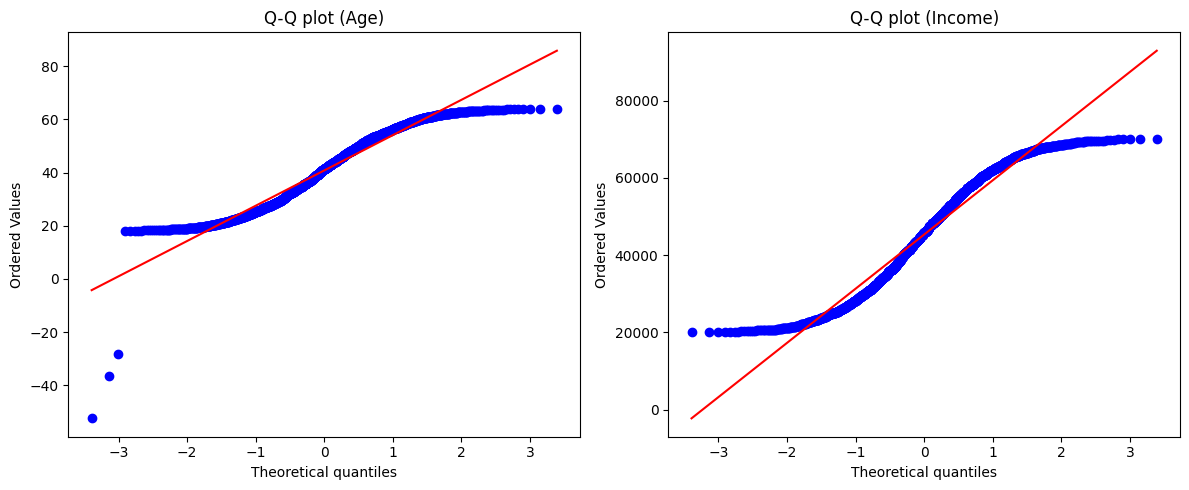

In [47]:
#Example 16 with Q-Q (Quantile-Quantile)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
stats.probplot(df['age'].dropna(), dist='norm', plot=axes[0])
axes[0].set_title('Q-Q plot (Age)')
stats.probplot(df['income'].dropna(), dist='norm', plot=axes[1])
axes[1].set_title('Q-Q plot (Income)')
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Regplot: Income vs Loan')

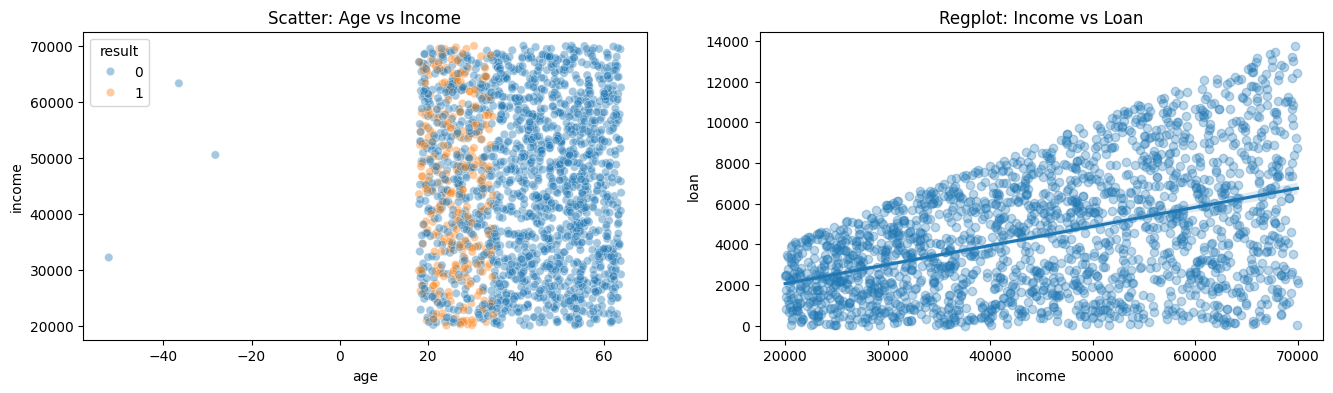

In [48]:
#Example 17 ( Multiple Scatter Plots )
fig, axes = plt.subplots(1, 2, figsize=(16,4))
sns.scatterplot(data=df, x='age', y='income', hue='result', alpha=0.4, ax=axes[0])
axes[0].set_title('Scatter: Age vs Income')
sns.regplot(data=df, x='income', y='loan', scatter_kws={'alpha':0.3}, ax=axes[1])
axes[1].set_title('Regplot: Income vs Loan')

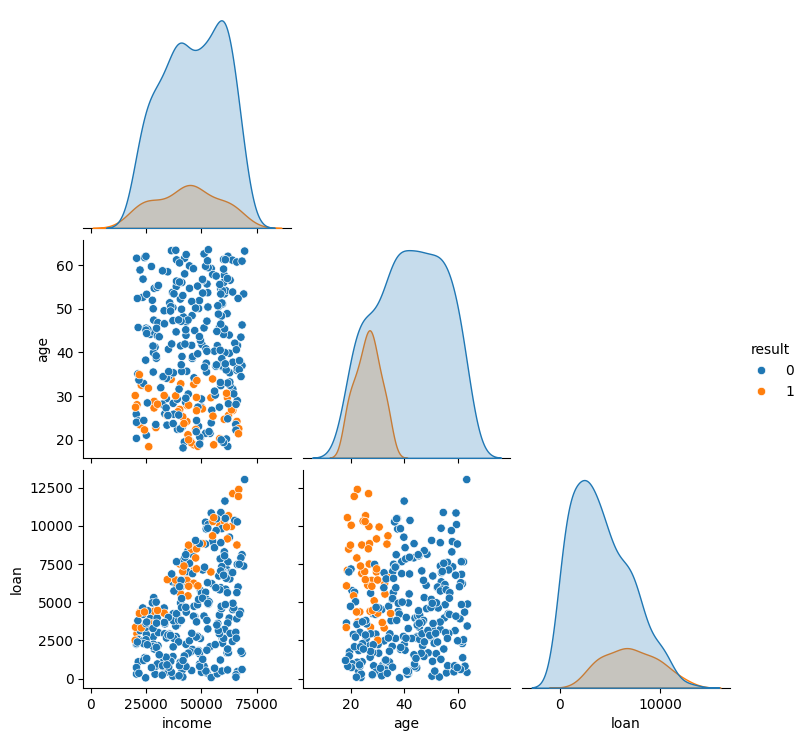

In [49]:
#Example 18 - Multivariate Analysis using Credit Dataset
sns.pairplot(df.sample(300, random_state=42)[['income', 'age', 'loan', 'result']], hue='result', diag_kind='kde', corner=True)
plt.show()

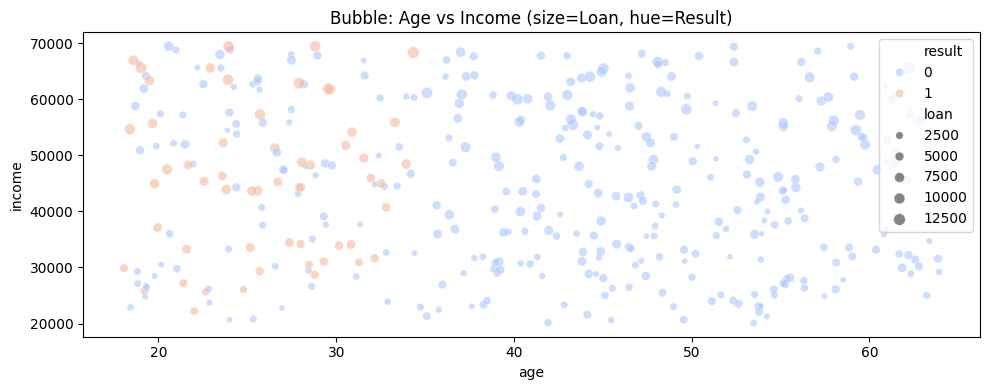

In [50]:
#Example 19 - Bubble
fig, ax = plt.subplots(figsize=(10,4))
sns.scatterplot(data=df.sample(400, random_state=3), x='age', y='income', size='loan', hue='result', palette='coolwarm', alpha=0.6, ax=ax)
ax.set_title('Bubble: Age vs Income (size=Loan, hue=Result)')
plt.tight_layout()
plt.show()

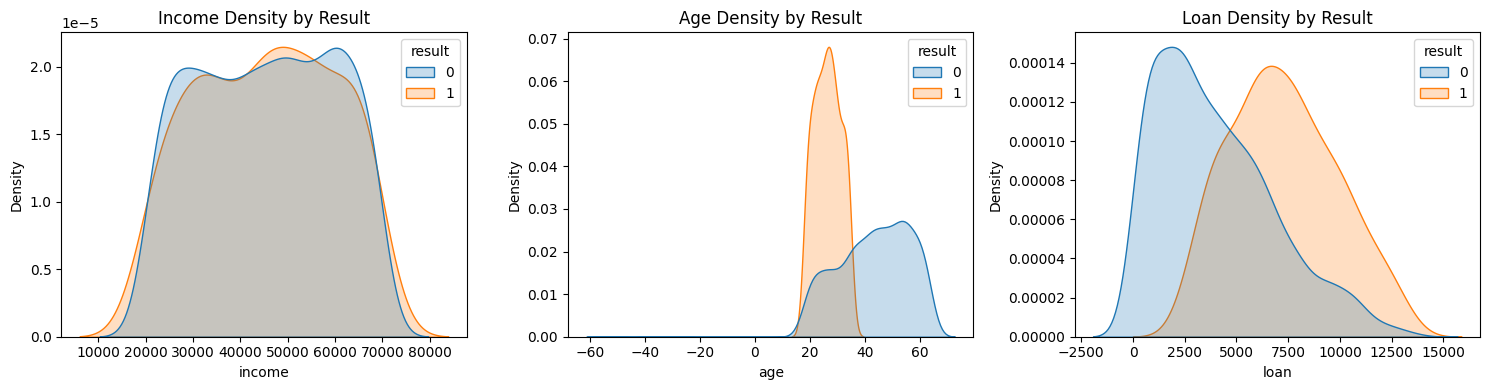

In [51]:
#Example 20 ( Density by Result )
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.kdeplot(data=df, x='income', hue='result', fill=True, common_norm=False, ax=axes[0])
axes[0].set_title('Income Density by Result')

sns.kdeplot(data=df, x='age', hue='result', fill=True, common_norm=False, ax=axes[1])
axes[1].set_title('Age Density by Result')

sns.kdeplot(data=df, x='loan', hue='result', fill=True, common_norm=False, ax=axes[2])
axes[2].set_title('Loan Density by Result')

plt.tight_layout()
plt.show()

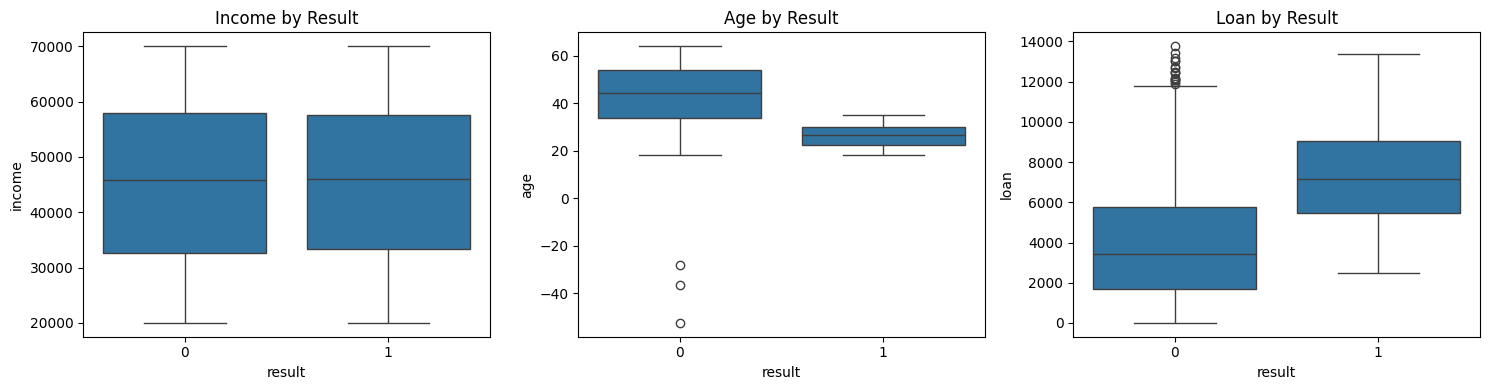

In [52]:
#Example 21 ( Boxplots by Result )
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x='result', y=col, ax=ax)
    ax.set_title(f'{col.capitalize()} by Result')
plt.tight_layout()
plt.show()

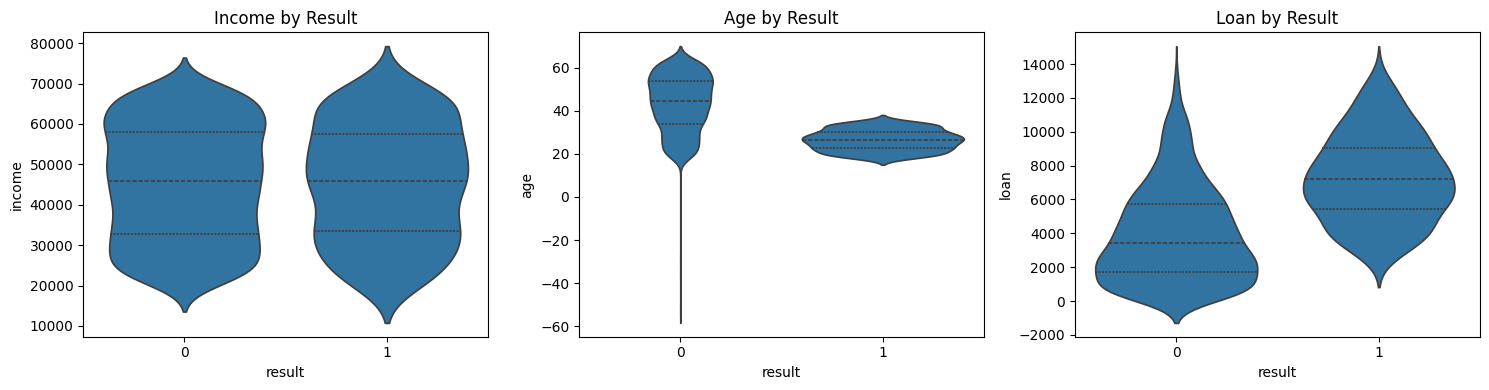

In [53]:
#Example 22 ( Violin Plots by Result )
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.violinplot(data=df, x='result', y=col, inner='quartile', ax=ax)
    ax.set_title(f'{col.capitalize()} by Result')
plt.tight_layout()
plt.show()

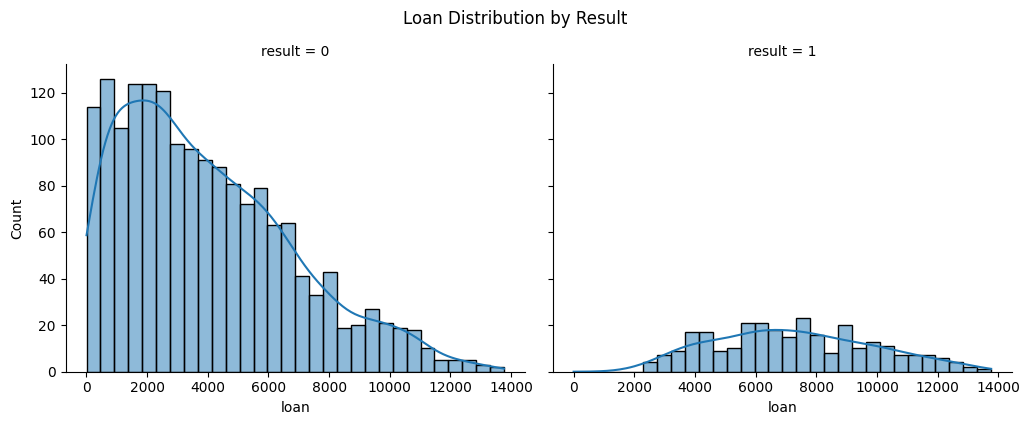

In [54]:
#Example 23 ( Histograms by Result with FacetGrid )
g = sns.displot(data=df, x='loan', col='result', kde=True, bins=30, height=4, aspect=1.3)
g.fig.suptitle('Loan Distribution by Result', y=1.05)
plt.show()

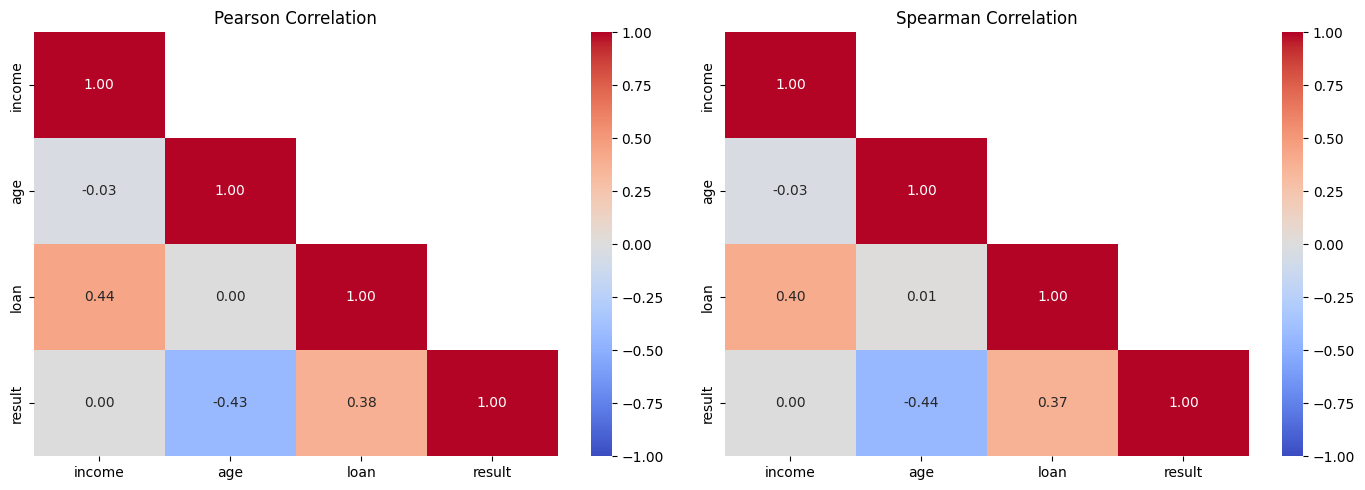

In [55]:
#Example 24 ( Correlation Heatmap: Pearson vs Spearman )
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, method in zip(axes, ['pearson', 'spearman']):
    corr = df[num_cols + ['result']].corr(method=method)
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)  # Hide the Repeated Upper Triangle
    sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
    ax.set_title(f'{method.capitalize()} Correlation')
plt.tight_layout()
plt.show()

In [56]:
#Example 25 ( 3D Scatter Plot )
sample = df.dropna().sample(500, random_state=42).astype({'result': str})
fig = px.scatter_3d(sample, x='age', y='income', z='loan', color='result', opacity=0.7)
fig.show()

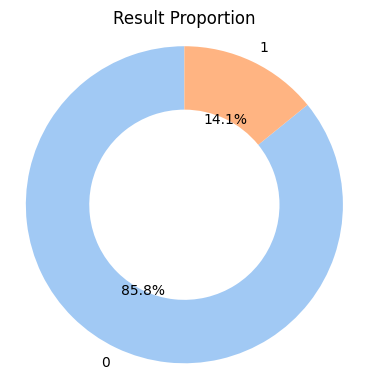

Imbalance ratio ( majority : minority ) = 6.1 : 1


In [57]:
#Example 26 ( Donut Chart and Class Imbalance Ratio )
counts = df['result'].value_counts()
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90, colors=sns.color_palette('pastel'), wedgeprops={'width': 0.4})
ax.axis('equal')
ax.set_title('Result Proportion')
plt.show()
print(f'Imbalance ratio ( majority : minority ) = {counts.max() / counts.min():.1f} : 1')

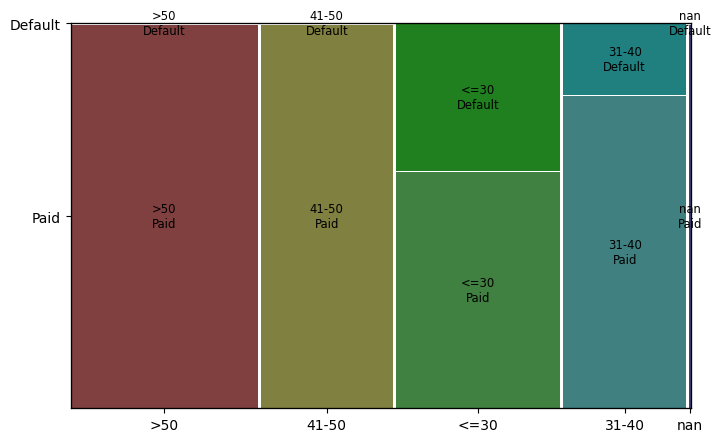

In [58]:
#Example 27 ( Mosaic Plot - Age Group vs Result )
temp_df = df.copy()
temp_df['age_group'] = pd.cut(
    temp_df['age'],
    bins=[0, 30, 40, 50, 120],
    labels=['<=30', '31-40', '41-50', '>50']
).astype(str)

temp_df['result_label'] = temp_df['result'].map({0: 'Paid', 1: 'Default'}).astype(str)
fig, ax = plt.subplots(figsize=(8, 5))
mosaic(temp_df, ['age_group', 'result_label'], ax=ax)
plt.show()

### **05. Time Series Analysis**

In [59]:
#Load the Time Series Dataset ( Airline Passengers )
flights = sns.load_dataset('flights')
flights.head()

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121


In [60]:
#Create the Datetime Index ( Monthly Frequency )
flights['date'] = pd.to_datetime(flights['year'].astype(str) + '-' + flights['month'].astype(str).str[:3], format='%Y-%b')
ts = flights.set_index('date')['passengers'].sort_index().asfreq('MS')
ts.head()

,passengers
date,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


In [61]:
#Time Series Structure ( Range, Frequency, Gaps and Duplicates )
print('Start:', ts.index.min().date(), '| End:', ts.index.max().date())
print('Observations:', len(ts))
print('Inferred frequency:', pd.infer_freq(ts.index))
print('Missing timestamps / values:', ts.isnull().sum())
print('Duplicated timestamps:', ts.index.duplicated().sum())
# If gaps exist: ts.interpolate(method='time') fills them using the neighbors in time

Start: 1949-01-01 | End: 1960-12-01
Observations: 144
Inferred frequency: MS
Missing timestamps / values: 0
Duplicated timestamps: 0


In [62]:
#Create Calendar Features
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
ts_df = ts.to_frame()
ts_df['year'] = ts_df.index.year
ts_df['quarter'] = ts_df.index.quarter
ts_df['month'] = ts_df.index.month
ts_df['month_name'] = ts_df['month'].map(lambda m: month_labels[m - 1])
ts_df.head()

,passengers,year,quarter,month,month_name
date,,,,,
1949-01-01,112,1949,1,1,Jan
1949-02-01,118,1949,1,2,Feb
1949-03-01,132,1949,1,3,Mar
1949-04-01,129,1949,2,4,Apr
1949-05-01,121,1949,2,5,May


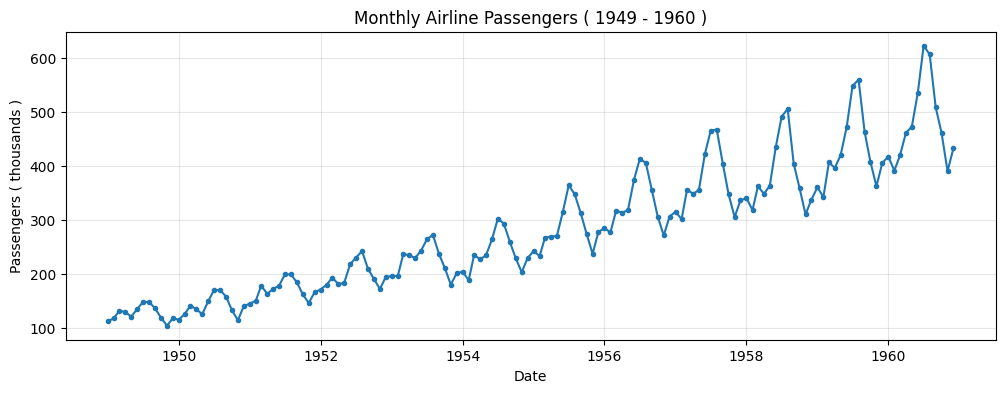

In [63]:
#Example 28 ( Line Plot of the Series )
plt.figure(figsize=(12, 4))
plt.plot(ts, marker='o', markersize=3)
plt.title('Monthly Airline Passengers ( 1949 - 1960 )')
plt.xlabel('Date')
plt.ylabel('Passengers ( thousands )')
plt.grid(alpha=0.3)
plt.show()

In [64]:
#Example 29 ( Interactive Line Plot with Range Slider )
fig = px.line(ts_df.reset_index(), x='date', y='passengers', title='Monthly Airline Passengers')
fig.update_xaxes(rangeslider_visible=True)
fig.show()

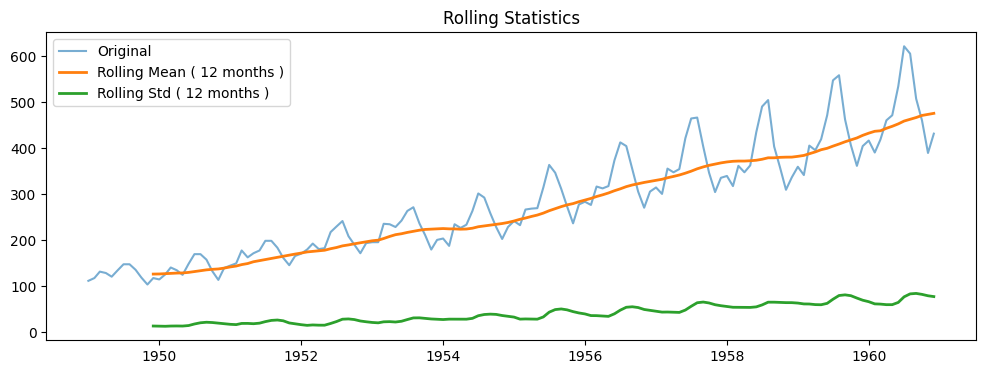

In [65]:
#Example 30 ( Rolling Mean and Rolling Standard Deviation )
roll_mean = ts.rolling(window=12).mean()
roll_std = ts.rolling(window=12).std()

plt.figure(figsize=(12, 4))
plt.plot(ts, label='Original', alpha=0.6)
plt.plot(roll_mean, label='Rolling Mean ( 12 months )', linewidth=2)
plt.plot(roll_std, label='Rolling Std ( 12 months )', linewidth=2)
plt.title('Rolling Statistics')
plt.legend()
plt.show()

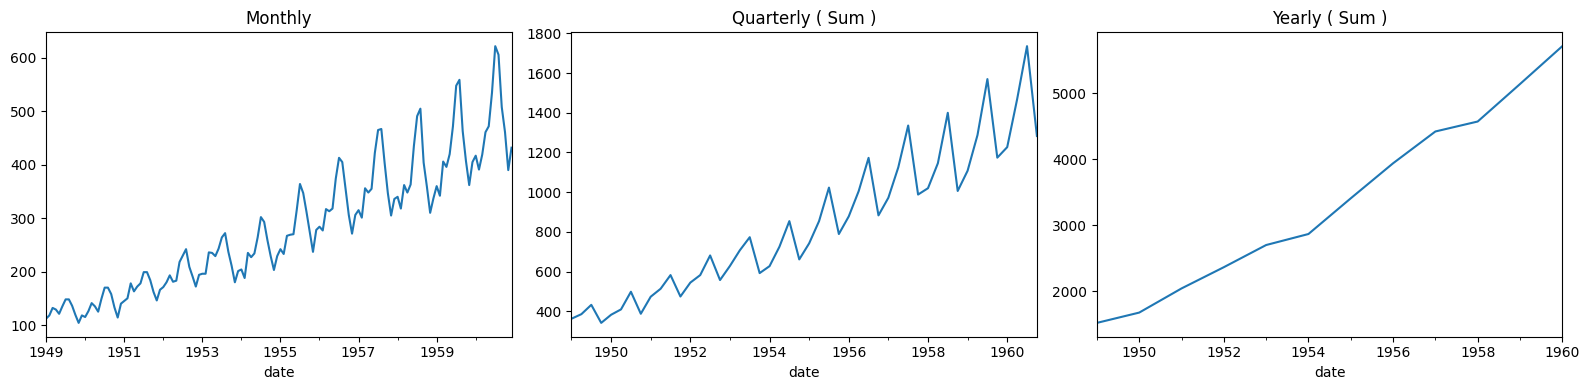

In [66]:
#Example 31 - Resampling ( Monthly, Quarterly and Yearly )
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ts.plot(ax=axes[0], title='Monthly')
ts.resample('QS').sum().plot(ax=axes[1], title='Quarterly ( Sum )')
ts.resample('YS').sum().plot(ax=axes[2], title='Yearly ( Sum )')
plt.tight_layout()
plt.show()

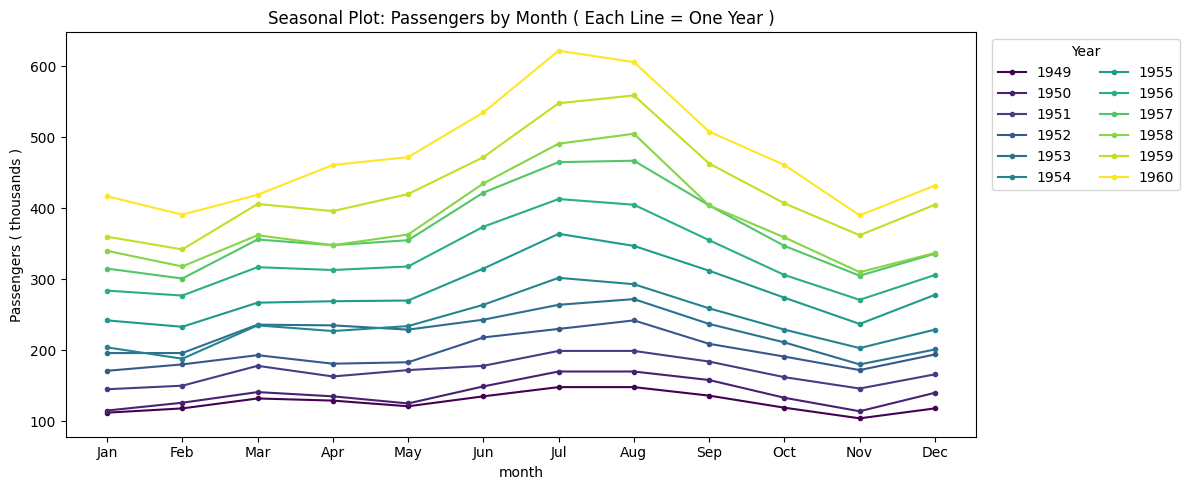

In [67]:
#Example 32 - Seasonality ( One Line per Year )
seasonal_pivot = ts_df.pivot_table(index='month', columns='year', values='passengers')
ax = seasonal_pivot.plot(figsize=(12, 5), colormap='viridis', marker='o', markersize=3)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_labels)
ax.set_title('Seasonal Plot: Passengers by Month ( Each Line = One Year )')
ax.set_ylabel('Passengers ( thousands )')
ax.legend(title='Year', ncol=2, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

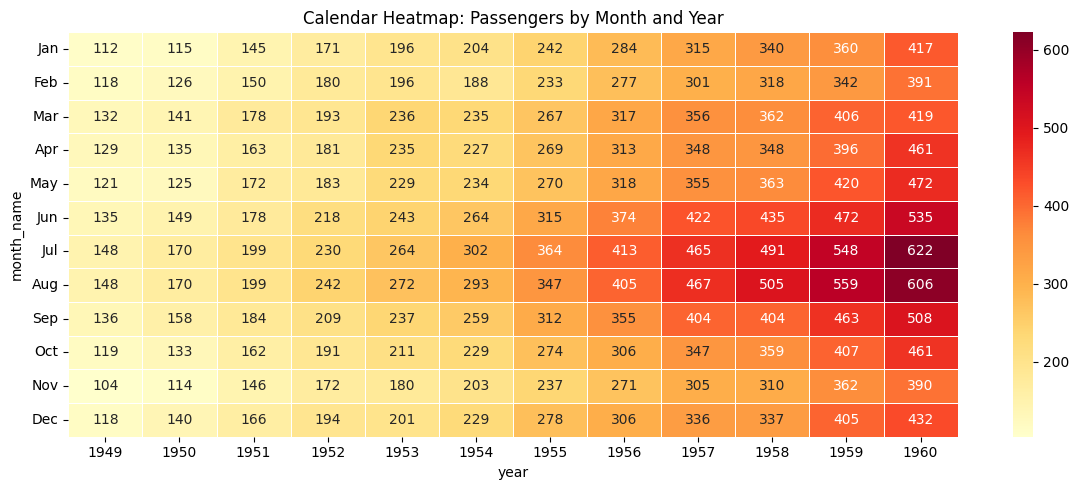

In [68]:
#Example 33 - Calendar Heatmap ( Month x Year )
calendar_pivot = ts_df.pivot_table(index='month_name', columns='year', values='passengers').reindex(month_labels)
plt.figure(figsize=(12, 5))
sns.heatmap(calendar_pivot, cmap='YlOrRd', annot=True, fmt='.0f', linewidths=0.5)
plt.yticks(rotation=0)
plt.title('Calendar Heatmap: Passengers by Month and Year')
plt.tight_layout()
plt.show()

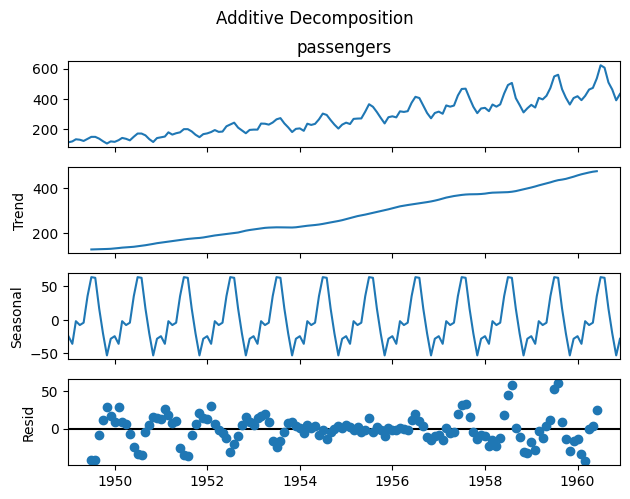

In [69]:
#Example 34 - Classical Decomposition ( Additive: Series = Trend + Seasonal + Residual )
dec_add = seasonal_decompose(ts, model='additive', period=12)
dec_add.plot()
plt.suptitle('Additive Decomposition', y=1.03)
plt.show()

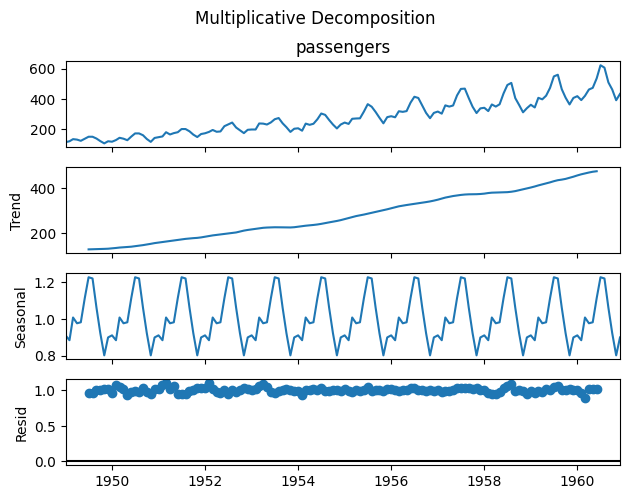

In [70]:
#Example 35 - Classical Decomposition ( Multiplicative: Series = Trend x Seasonal x Residual )
dec_mul = seasonal_decompose(ts, model='multiplicative', period=12)
dec_mul.plot()
plt.suptitle('Multiplicative Decomposition', y=1.03)
plt.show()

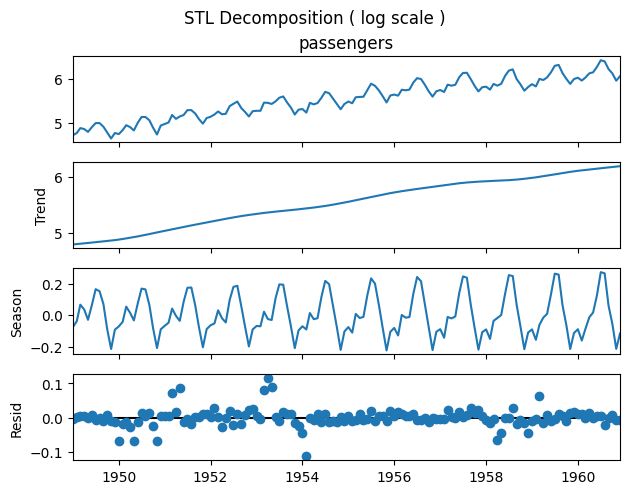

In [71]:
#Example 36 - STL Decomposition ( Robust to Outliers, Applied to the Log of the Series )
stl = STL(np.log(ts), period=12, robust=True).fit()
stl.plot()
plt.suptitle('STL Decomposition ( log scale )', y=1.02)
plt.show()

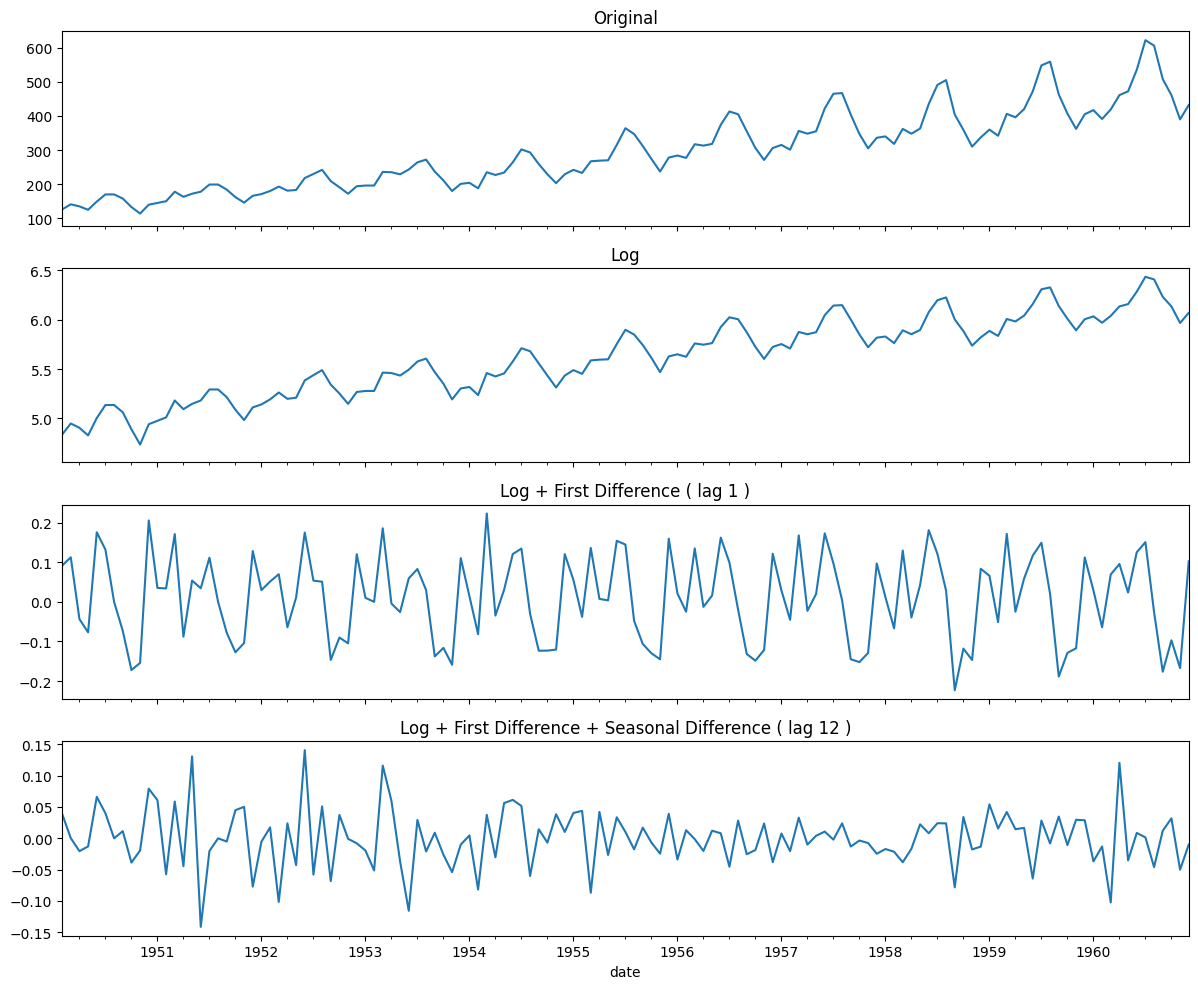

In [72]:
#Example 37 - Stationarity ( Log and Differencing )
ts_log = np.log(ts)                      # Stabilizes the variance
ts_log_diff = ts_log.diff().dropna()     # Removes the trend
ts_log_diff12 = ts_log.diff().diff(12).dropna()  # Removes the trend and the yearly seasonality

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
ts.plot(ax=axes[0], title='Original')
ts_log.plot(ax=axes[1], title='Log')
ts_log_diff.plot(ax=axes[2], title='Log + First Difference ( lag 1 )')
ts_log_diff12.plot(ax=axes[3], title='Log + First Difference + Seasonal Difference ( lag 12 )')
plt.tight_layout()
plt.show()

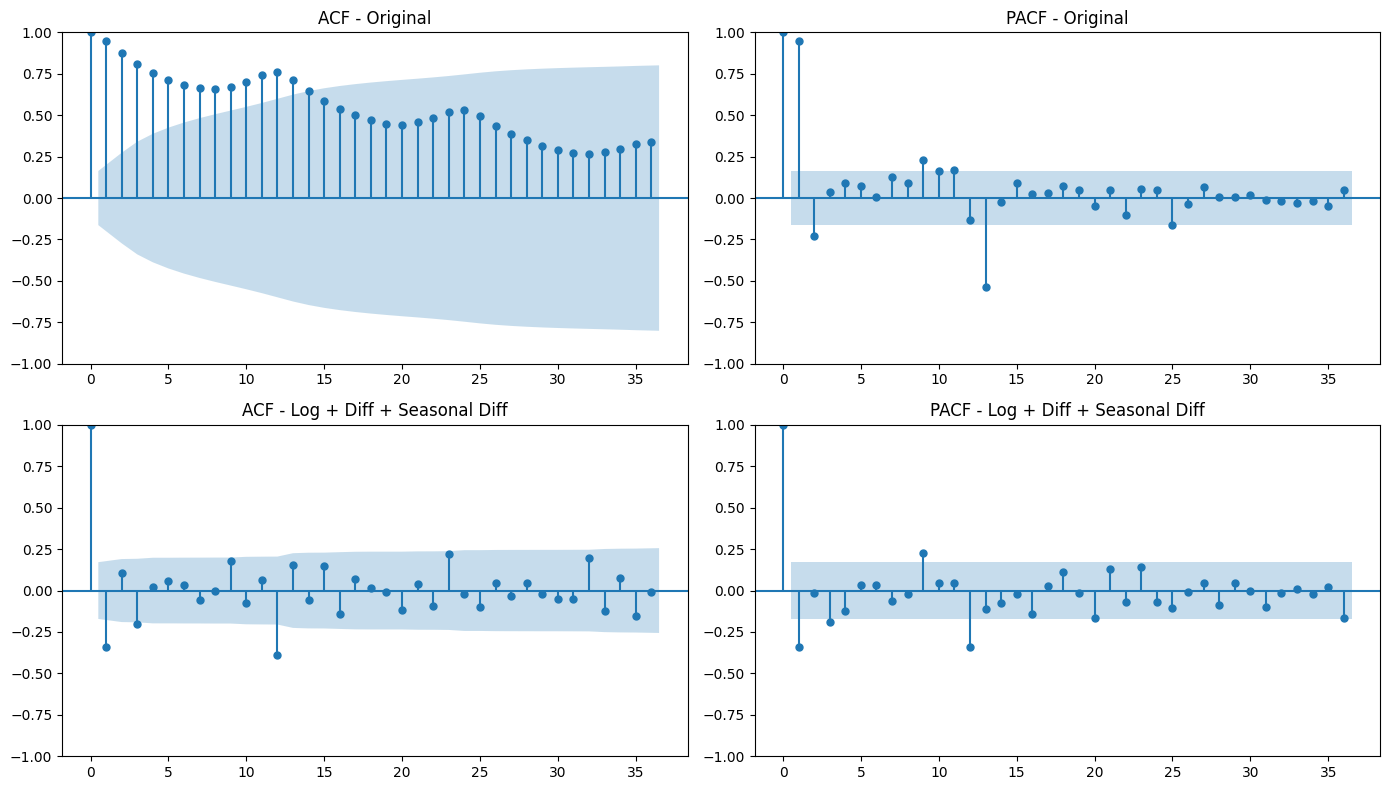

In [73]:
#Example 38 - Autocorrelation ( ACF and PACF )
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
plot_acf(ts, lags=36, ax=axes[0, 0])
axes[0, 0].set_title('ACF - Original')
plot_pacf(ts, lags=36, ax=axes[0, 1])
axes[0, 1].set_title('PACF - Original')
plot_acf(ts_log_diff12, lags=36, ax=axes[1, 0])
axes[1, 0].set_title('ACF - Log + Diff + Seasonal Diff')
plot_pacf(ts_log_diff12, lags=36, ax=axes[1, 1])
axes[1, 1].set_title('PACF - Log + Diff + Seasonal Diff')
plt.tight_layout()
plt.show()

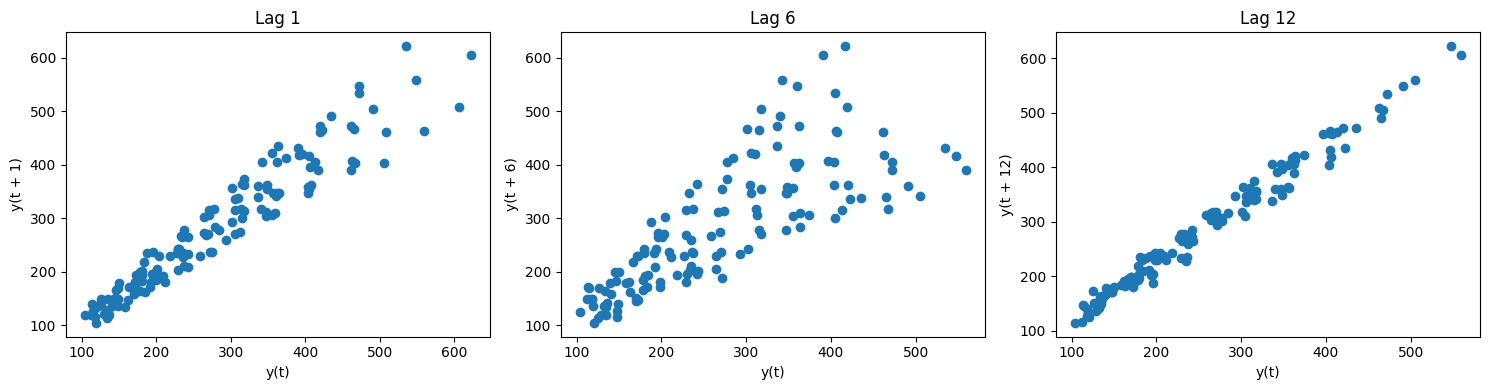

In [74]:
#Example 39 - Lag Plots ( Points on the Diagonal = Strong Autocorrelation )
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, lag in zip(axes, [1, 6, 12]):
    pd.plotting.lag_plot(ts, lag=lag, ax=ax)
    ax.set_title(f'Lag {lag}')
plt.tight_layout()
plt.show()

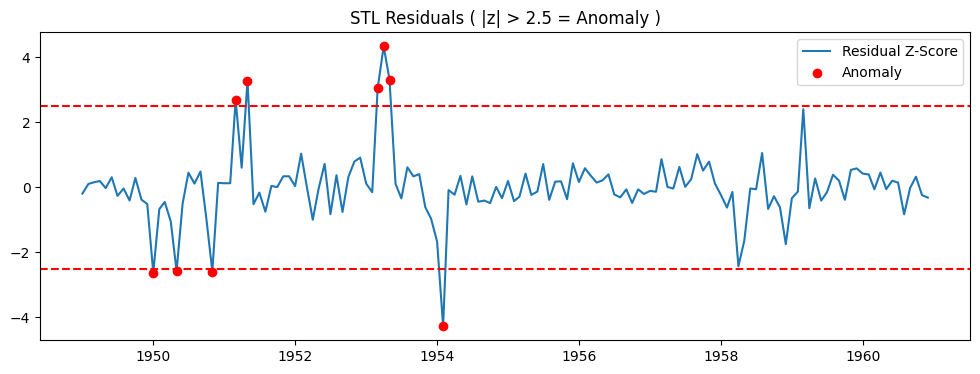

Anomalies found: 9


,resid
date,
1950-01-01,-2.63
1950-05-01,-2.58
1950-11-01,-2.59
1951-03-01,2.70
1951-05-01,3.28
1953-03-01,3.05
1953-04-01,4.35
1953-05-01,3.32
1954-02-01,-4.28


In [75]:
#Example 40 - Anomaly Detection in the Series ( STL Residual Z-Score )
stl = STL(np.log(ts), period=12, robust=True).fit()

resid = stl.resid
resid_z = (resid - resid.mean()) / resid.std()
anomalies = resid_z[resid_z.abs() > 2.5]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(resid_z, label='Residual Z-Score')
ax.axhline(2.5, color='red', linestyle='--')
ax.axhline(-2.5, color='red', linestyle='--')
ax.scatter(anomalies.index, anomalies.values, color='red', zorder=3, label='Anomaly')
ax.set_title('STL Residuals ( |z| > 2.5 = Anomaly )')
ax.legend()
plt.show()
print('Anomalies found:', len(anomalies))
anomalies.round(2)

### **06. Time Series Analysis - With Random Sample**

In [76]:
#Create a Sample DataSet with the First Column
date_rng = pd.date_range(start='2025-01-01', periods=50, freq='D')
df = pd.DataFrame(date_rng, columns=['date'])
df['date'] = pd.to_datetime(df['date'])
df = df.set_index('date')

In [77]:
# Generate Random data with trend, seasonality, and randomness
np.random.seed(42)
df['attribute_1'] = np.linspace(10, 20, 50) + np.sin(np.linspace(0, 2 * np.pi, 50) * 5) * 2 + np.random.randn(50)
df['attribute_2'] = np.linspace(50, 60, 50) + np.cos(np.linspace(0, 2 * np.pi, 50) * 3) * 3 + np.random.randn(50) * 0.5
df['attribute_3'] = np.random.randn(50) * 5 + 100

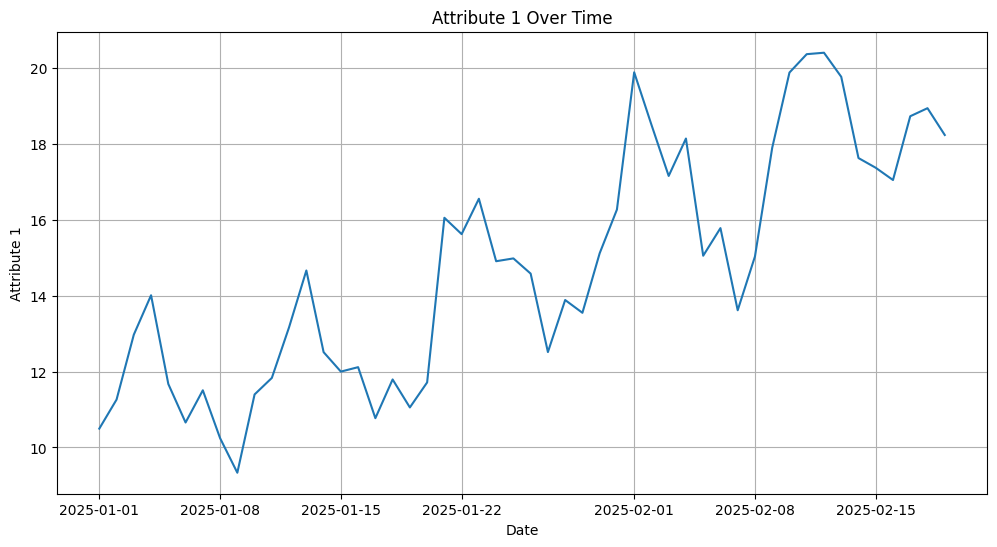

In [78]:
#Example 41
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x=df.index, y='attribute_1')
plt.title('Attribute 1 Over Time')
plt.xlabel('Date')
plt.ylabel('Attribute 1')
plt.grid(True)
plt.show()

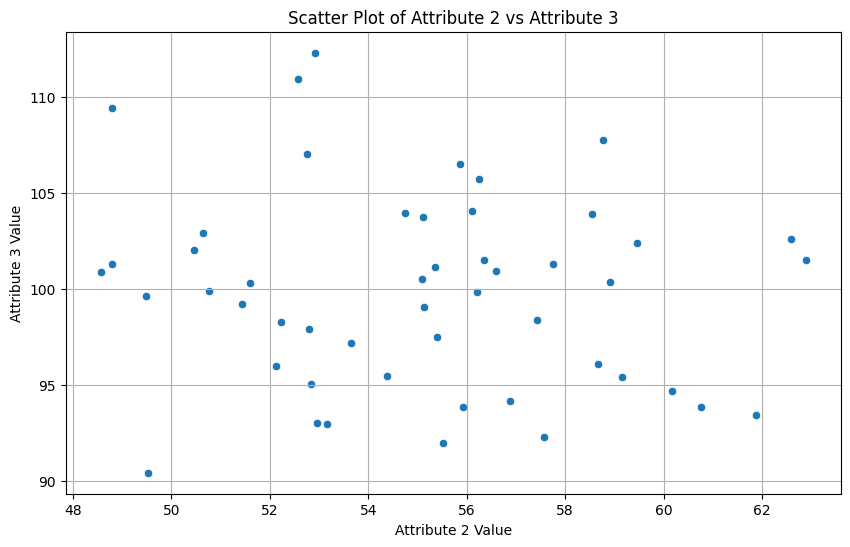

In [79]:
#Example 42
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='attribute_2', y='attribute_3')
plt.title('Scatter Plot of Attribute 2 vs Attribute 3')
plt.xlabel('Attribute 2 Value')
plt.ylabel('Attribute 3 Value')
plt.grid(True)
plt.show()

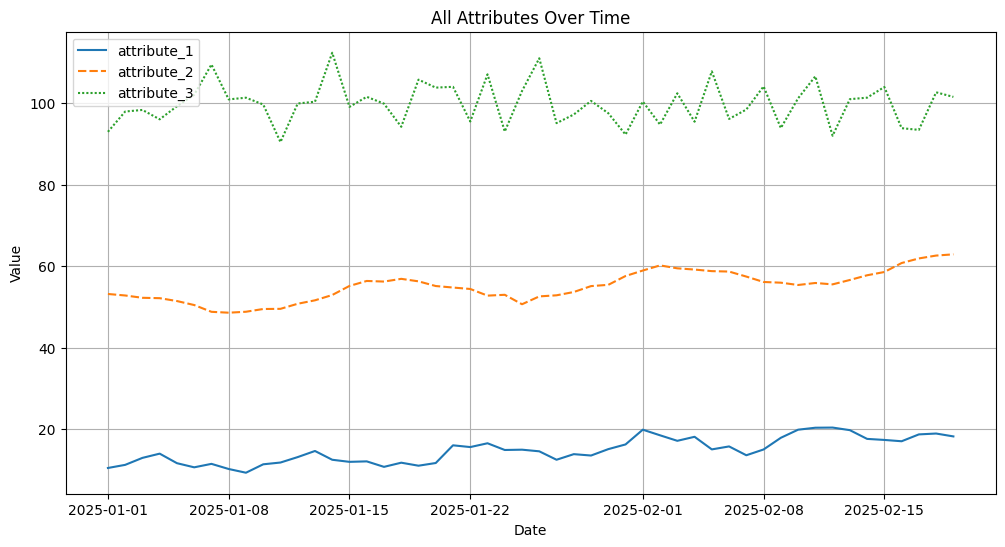

In [80]:
#Exemplo 43
plt.figure(figsize=(12, 6))
sns.lineplot(data=df)
plt.title('All Attributes Over Time')
plt.xlabel('Date')
plt.ylabel('Value')
plt.grid(True)
plt.show()